# **CA3** - Classification of Wine

# **Group 6** - Narges Zareigolbaghi & Kachina Aschenberg Øwre 
### **Kaggle names - nargeszareigolbaghi & kachasch**

**Use machine learning to develop a system/classifier capable of distinguishing between high-quality and low-quality wines based on measurable characteristics.**

*Your task is to create a classifier that uses the available wine characteristics to sort the wines into the correct categories.*

*The dataset contains several physicochemical properties of wine that can be used to predict its quality. These properties describe characteristics such as acidity, sugar content, density, sulphates, alcohol level, and other chemical measurements.*

*The success of your classification system depends on your ability to explore the data, identify useful patterns, and train a model that can accurately distinguish between good and bad wines.*

Sample: one row, one wine

Feature: Attribute, variable, column (pH, alcohol)

Target: quality (0=bad, 1=good)

Feature matrix: X, all columns together (835 rows x 11 columns)

Target vector: y, the target column (835 values of 0 or 1)

#### Sources and acknowledgements

Material in this notebook that did not originate with us:

- The `evaluate` function and the tuning-loop pattern follow the approach shown in the lecture notebooks `03_svm_gridsearch_iris.ipynb` and `03_knn_hyperparameters_validation_set.ipynb`, and the procedure set out in `CA3_Workflow.pdf`.
- The code in section 5, section 8 and section 9, the docstring on `evaluate`, the axis labels and titles added to the plots in sections 3 and 6, and the accompanying `CA3_Group6.py` were drafted with assistance from an AI assistant (Claude, Anthropic) and then reviewed by us.
- Discussion of the results — how to compare models on the same splits, why the maximum over many settings is biased upward, and how to read the train/validation gap — also drew on that assistance.

The dataset is the wine quality data supplied with the assignment.

### 1. Imports

In [26]:
import numpy as np                 # numbers and arrays
import pandas as pd                # tables (DataFrames)
import matplotlib.pyplot as plt    # basic plotting
import seaborn as sns              # nicer statistical plots on top of matplotlib
import sklearn as skl              # machine learning library

from sklearn.model_selection import train_test_split # splits data into training and test sets
from sklearn.preprocessing import StandardScaler # rescales features to have mean 0 and variance 1
from sklearn.linear_model import Perceptron, LogisticRegression # linear classifiers, baseline for comparison and neural networks
from sklearn.svm import SVC     # support vector machine, a more powerful linear classifier
from sklearn.tree import DecisionTreeClassifier # decision tree, a non-linear classifier
from sklearn.ensemble import RandomForestClassifier     # random forest, a more powerful non-linear classifier
from sklearn.neighbors import KNeighborsClassifier  # k-nearest neighbors, a non-linear classifier

### 2. Reading data

In [27]:
train = pd.read_csv("train.csv")                 # 11 features + quality + Id
test = pd.read_csv("test.csv")                   # 11 features + Id, no quality
sample = pd.read_csv("sample_submission.csv")    # the format Kaggle expects
print("train:", train.shape, " test:", test.shape, " sample:", sample.shape)

# The feature columns: everything except the target and the row label
features = [col for col in train.columns if col not in ("quality", "Id")] 
print(len(features), "features:", features)

train: (835, 13)  test: (209, 12)  sample: (209, 2)
11 features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


Train.csv has 835 rows and 13 columns

### 3. Data exploration and visualisation

In [28]:
# Explore the training set
train.info()                       # shows entries, column types and memory usage
train.describe().T                 # .T turns the table: one row per feature, showing number of good and bad wines
print(train["quality"].value_counts()) # count of each quality value
print("Missing values:", train.isnull().sum().sum()) # total number of missing values in the training set
print("Duplicate rows (ignoring Id):", train.duplicated(subset=features + ["quality"]).sum()) # count of duplicate rows in the training set, ignoring the Id column

<class 'pandas.DataFrame'>
RangeIndex: 835 entries, 0 to 834
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         835 non-null    float64
 1   volatile acidity      835 non-null    float64
 2   citric acid           835 non-null    float64
 3   residual sugar        835 non-null    float64
 4   chlorides             835 non-null    float64
 5   free sulfur dioxide   835 non-null    float64
 6   total sulfur dioxide  835 non-null    float64
 7   density               835 non-null    float64
 8   pH                    835 non-null    float64
 9   sulphates             835 non-null    float64
 10  alcohol               835 non-null    float64
 11  quality               835 non-null    int64  
 12  Id                    835 non-null    int64  
dtypes: float64(11), int64(2)
memory usage: 84.9 KB
quality
1    418
0    417
Name: count, dtype: int64
Missing values: 0
Duplicate rows (ign

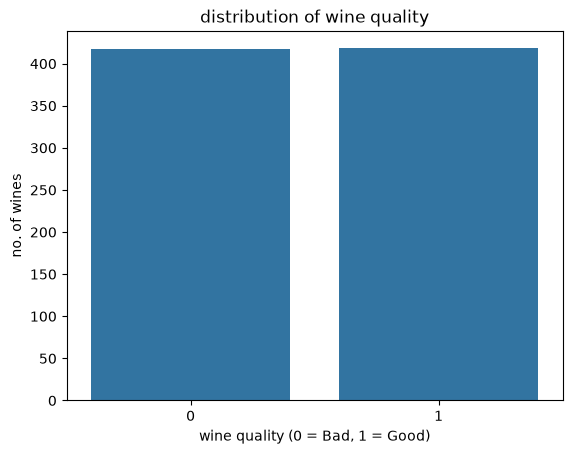

In [29]:
# distribution of wine quality  
sns.countplot(data=train, x="quality")
plt.xlabel("wine quality (0 = Bad, 1 = Good)")
plt.ylabel("no. of wines")
plt.title("distribution of wine quality")
plt.show()
# Wine quality between good and bad is eqally distributed 

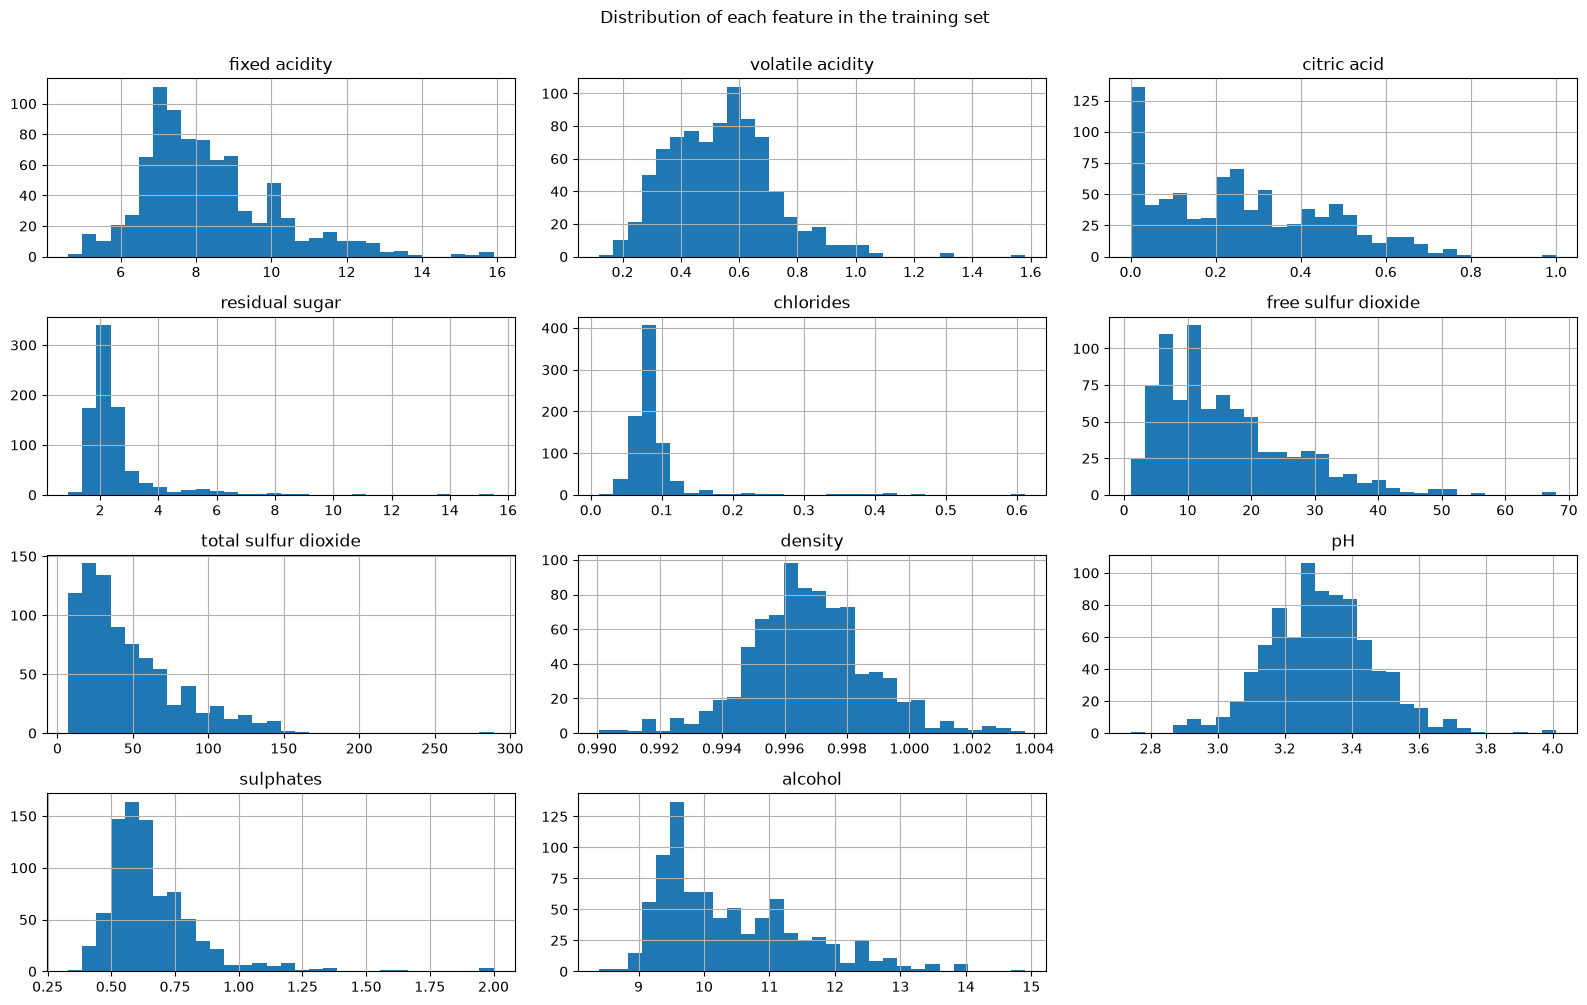

In [30]:
# Visualize the distribution of each feature in the training set
train[features].hist(figsize=(16, 10), bins=30)
plt.suptitle("Distribution of each feature in the training set", y=1.00)
plt.tight_layout()
plt.show()
# bell-shaped for pH and density 
# right skewed for residual sugar, chlorides, total sulfur dioxide

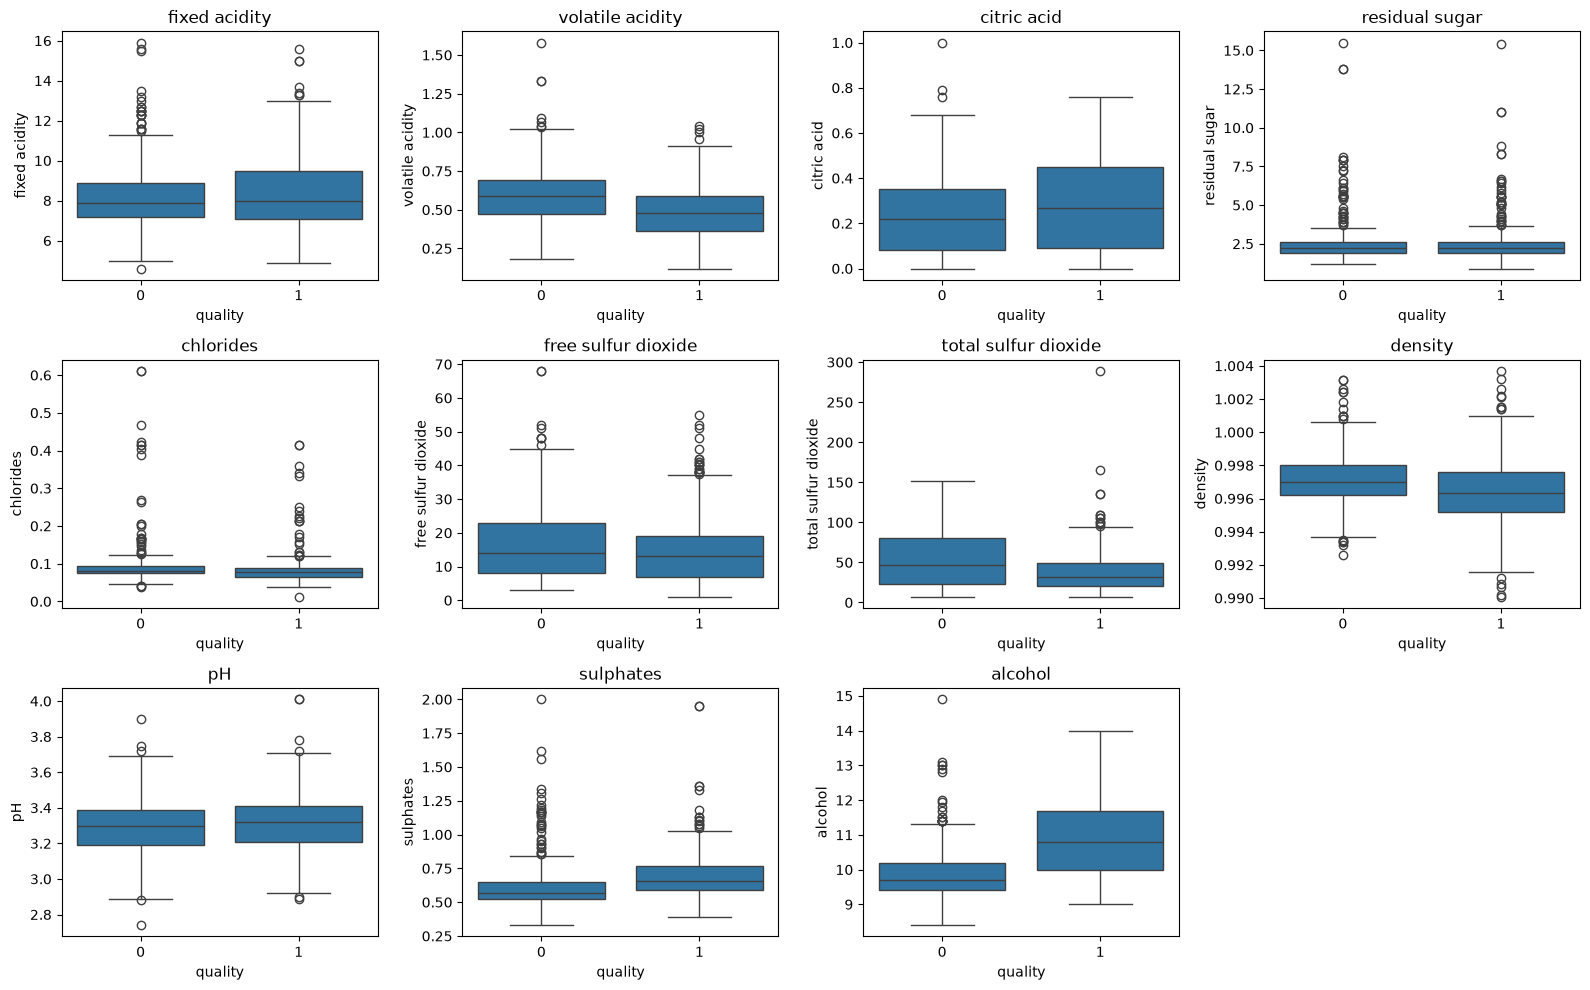

In [31]:
# Visualize the distribution of each feature in the training set, grouped by quality
fig, axes = plt.subplots(3, 4, figsize=(16, 10))     # 3 x 4 grid: 12 panels for 11 features
for ax, col in zip(axes.flatten(), features):          # one panel per feature
    sns.boxplot(data=train, x="quality", y=col, ax=ax)
    ax.set_title(col)
axes.flatten()[-1].set_visible(False)                  # hide the empty 12th panel
plt.tight_layout()
plt.show()

# Good quality wine (1) has generally higher alcohol level 
# Good quality wine usually has lower volatile acidity and total sulfur dioxide than bad-quality wines (0)
# Outlires in several features (e.g. residual sugar and chlorides)

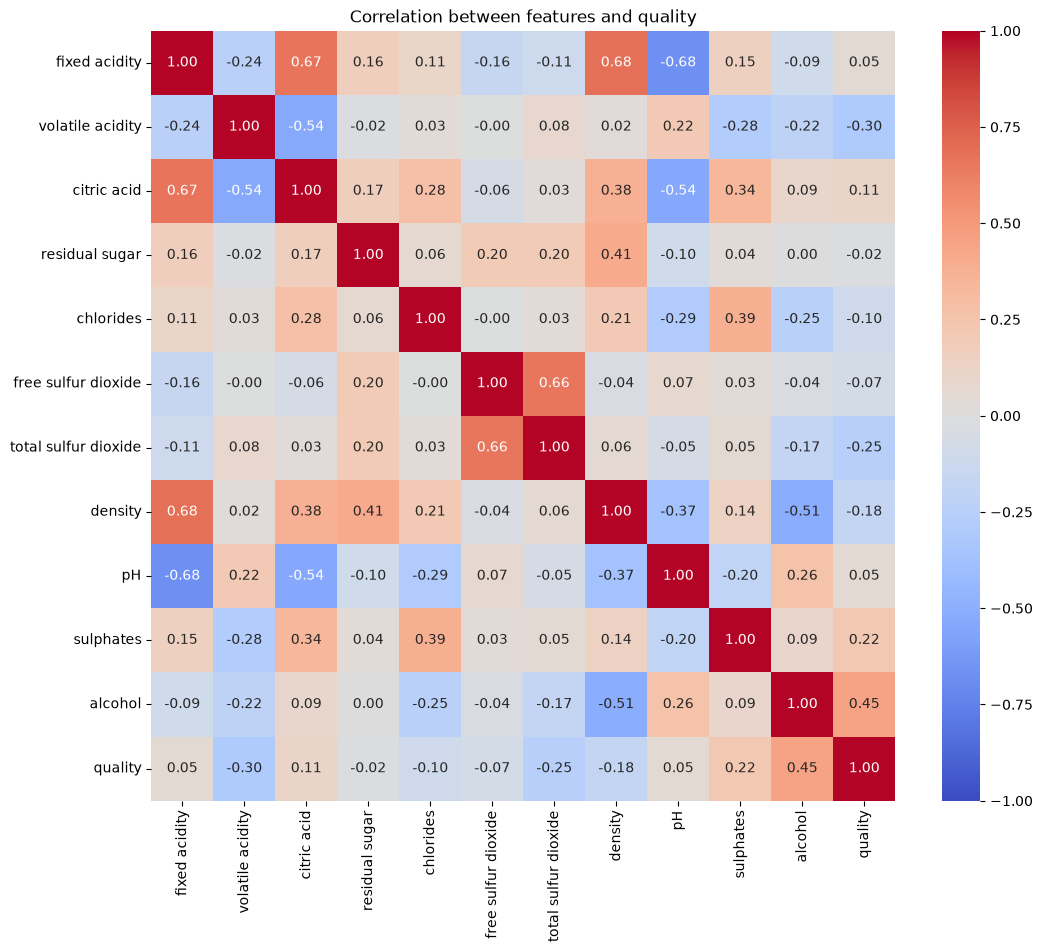

volatile acidity       -0.302238
total sulfur dioxide   -0.250267
density                -0.179263
chlorides              -0.103287
free sulfur dioxide    -0.074444
residual sugar         -0.020452
pH                      0.049578
fixed acidity           0.051339
citric acid             0.111017
sulphates               0.219372
alcohol                 0.451935
Name: quality, dtype: float64


''

In [32]:
# Correlation matrix and heatmap
corr = train[features + ["quality"]].corr() # compute correlation matrix for all features and target
plt.figure(figsize=(12, 10)) # set fig size
sns.heatmap(corr, annot=True, # gives each cell a the numeric value
            fmt=".2f", # format numbers to 2 decimal places
            cmap="coolwarm", 
            vmin=-1, 
            vmax=1) 
plt.title("Correlation between features and quality")
plt.show() 

print(corr["quality"].drop("quality").sort_values())   # correlation of each feature with quality
""

- Alcohol is the dominant single predictor at +0.452, so higher alcohol associates with good wine.
- Volatile acidity is the strongest negative at −0.302. It's the compound that makes wine taste of vinegar, so this assosiates with bad wine.
- No feature is strong enough to classify on its own. The largest is 0.452; a correlation that size explains roughly 20% of the variation, so this needs a model combining several features.
- All features and values ar valuable, because Pearson only detects linear relationships and a weak score here doesn't mean a feature is useless in combination.

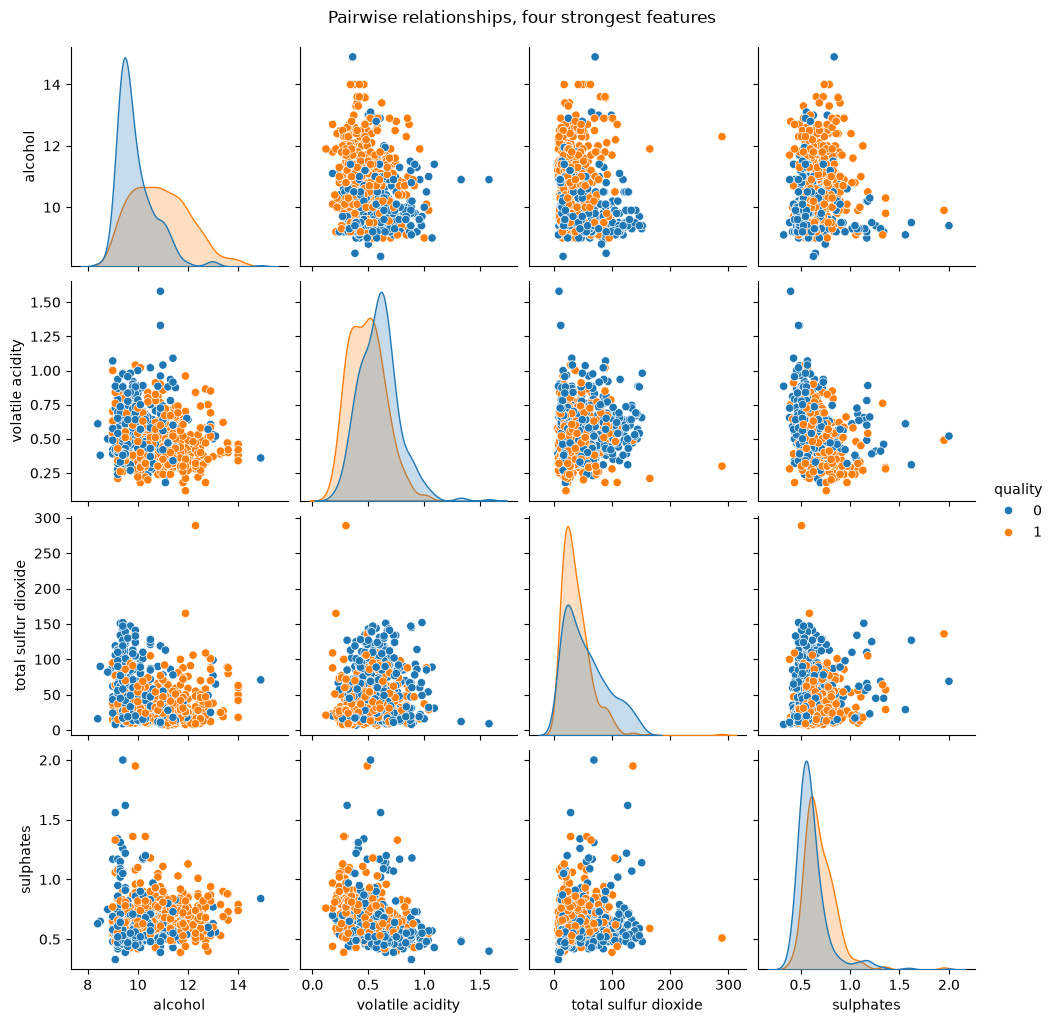

In [33]:
# The 4 features most correlated with quality, visualized by their pairwise relationships
top = corr["quality"].drop("quality").abs().sort_values(ascending=False).index[:4].tolist() 
    # take quality's correlations, drop the self-match, ignore the signs, rank strongest first, keep the names, take four.

g = sns.pairplot(train, vars=top, hue="quality")
g.figure.suptitle("Pairwise relationships, four strongest features", y=1.02) # pairwise scatterplots of the 4 features, colored by quality
plt.show()

# The distributions of the two quality classes highly overlap 
# although alcohol shows more separation
# combining multiple features may improve classification

### 4. Data cleaning

In [34]:
data = train.drop(columns=["Id"]) # drop the Id column, if it was still there would be no duplicates, because every row has a unique Id.

# Check for duplicate rows with conflicting labels
duplicates = data.duplicated(subset=features, keep=False) # mark all rows that have the same features as another row
conflicts = data[duplicates].groupby(features)["quality"].nunique() # count how many different quality values each group of duplicate features has
print("Duplicate groups with conflicting labels:", (conflicts > 1).sum())

# Keep the first copy of every exact duplicate
data = data.drop_duplicates()
print("Rows after removing exact duplicates:", len(data))

Duplicate groups with conflicting labels: 0
Rows after removing exact duplicates: 760


In [35]:
print("Negative values:", (data[features] < 0).sum().sum()) # count of negative values in the features
print("pH outside 2.5 to 4.5:", ((data["pH"] < 2.5) | (data["pH"] > 4.5)).sum()) # count of pH values outside the range 2.5 to 4.5
print("Alcohol outside 5 to 16 %:", ((data["alcohol"] < 5) | (data["alcohol"] > 16)).sum()) # count of alcohol values outside the range 5 to 16 %

Negative values: 0
pH outside 2.5 to 4.5: 0
Alcohol outside 5 to 16 %: 0


In [36]:
z = (data[features] - data[features].mean()) / data[features].std() # compute the z-score for each feature in each row
print((z.abs() > 3).sum())                         # outliers per feature
outlier_rows = (z.abs() > 3).any(axis=1)           # True if ANY feature has |z| > 3
print("Rows with |z| > 3 in any feature:", outlier_rows.sum()) # count of rows with outliers in any feature

fixed acidity            7
volatile acidity         3
citric acid              1
residual sugar          15
chlorides               16
free sulfur dioxide      9
total sulfur dioxide     4
density                 10
pH                       4
sulphates               12
alcohol                  6
dtype: int64
Rows with |z| > 3 in any feature: 68


### 5. Data exploration and visualisation after cleaning

Rows before: 835  after: 760
quality
0    0.501
1    0.499
Name: proportion, dtype: float64


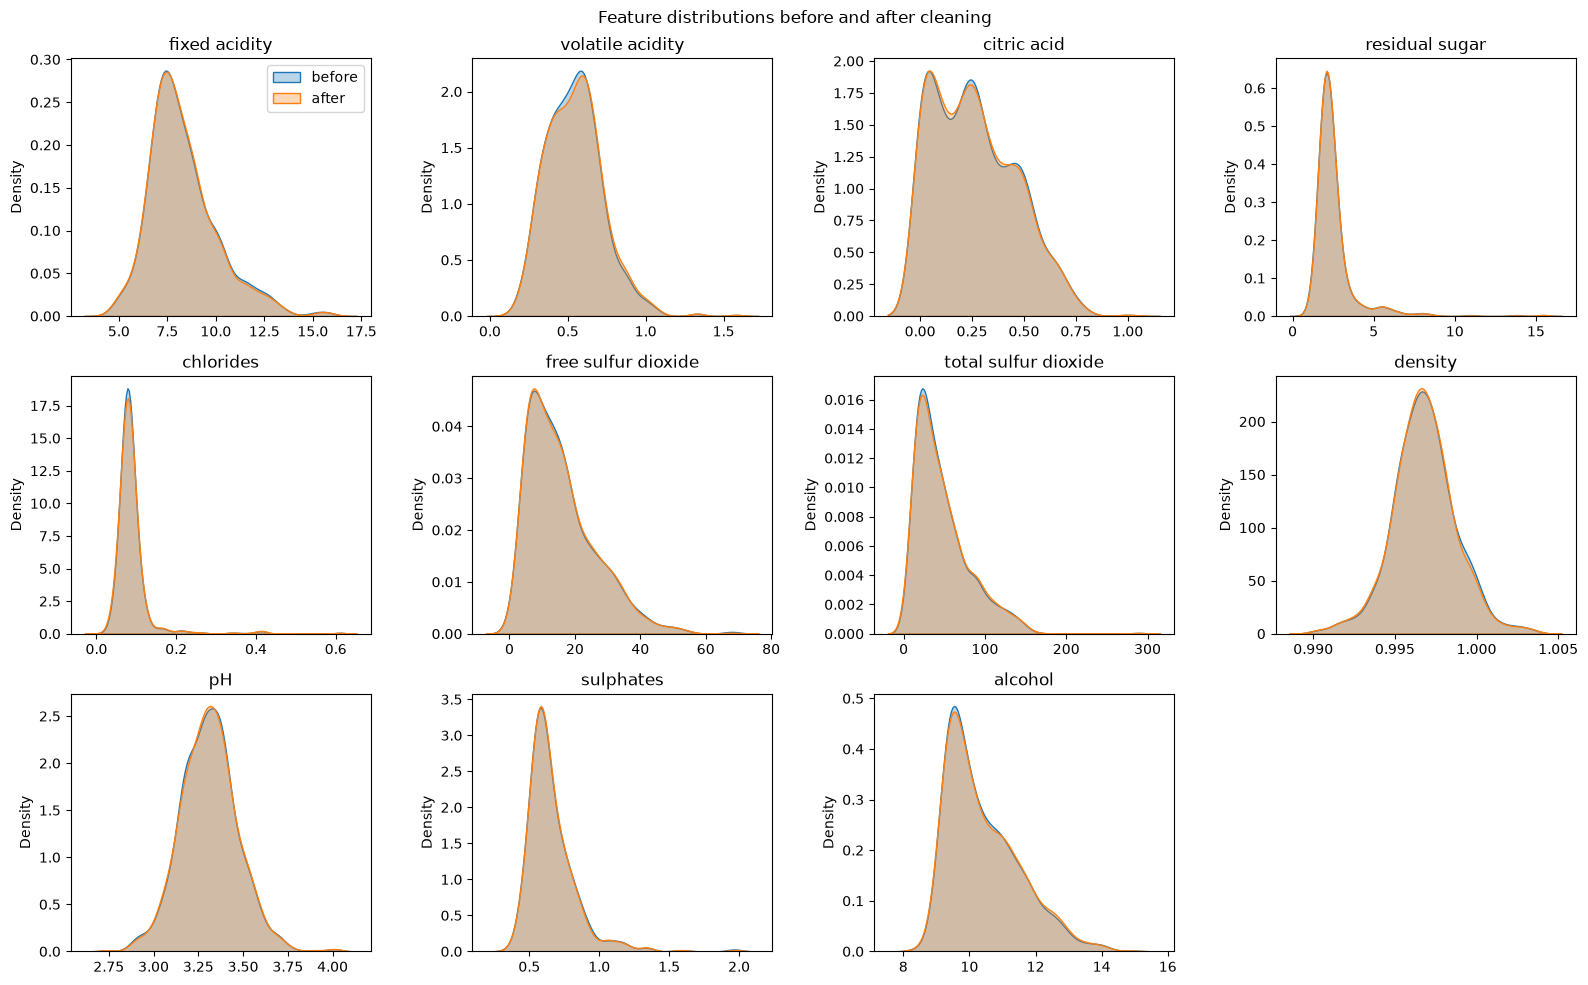

                      before  after  change
volatile acidity      -0.302 -0.299   0.004
total sulfur dioxide  -0.250 -0.262  -0.012
density               -0.179 -0.179  -0.000
chlorides             -0.103 -0.106  -0.003
free sulfur dioxide   -0.074 -0.089  -0.015
residual sugar        -0.020 -0.016   0.005
pH                     0.050  0.042  -0.008
fixed acidity          0.051  0.055   0.003
citric acid            0.111  0.118   0.007
sulphates              0.219  0.209  -0.010
alcohol                0.452  0.451  -0.001


In [37]:
# How much did cleaning change the data?
print("Rows before:", len(train), " after:", len(data))
print(data["quality"].value_counts(normalize=True).round(3))

# The same feature before and after, drawn on one pair of axes
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), features):
    sns.kdeplot(train[col], ax=ax, label="before", fill=True, alpha=.3)
    sns.kdeplot(data[col],  ax=ax, label="after",  fill=True, alpha=.3)
    ax.set_title(col)
    ax.set_xlabel("")
axes.flatten()[-1].set_visible(False)   # hide the empty 12th panel
axes.flatten()[0].legend()
fig.suptitle("Feature distributions before and after cleaning")
plt.tight_layout()
plt.show()

# Did any correlation with quality move?
before = train[features + ["quality"]].corr()["quality"].drop("quality")
after  = data[features + ["quality"]].corr()["quality"].drop("quality")
comparison = pd.DataFrame({"before": before, "after": after})
comparison["change"] = comparison["after"] - comparison["before"]
print(comparison.round(3).sort_values("after"))


Distribution: the balance was 50.1/49.9 before and 50.1/49.9 after. The duplicates that came out were split evenly between the classes.

### 6. Data preprocessing

In [38]:
# Makning the feature matrix and target vector for training the model

X = data[features].to_numpy() # one row per wine, one column per feature (760, 11)
y = data["quality"].to_numpy() # one row per wine, one column per target variable (760,)

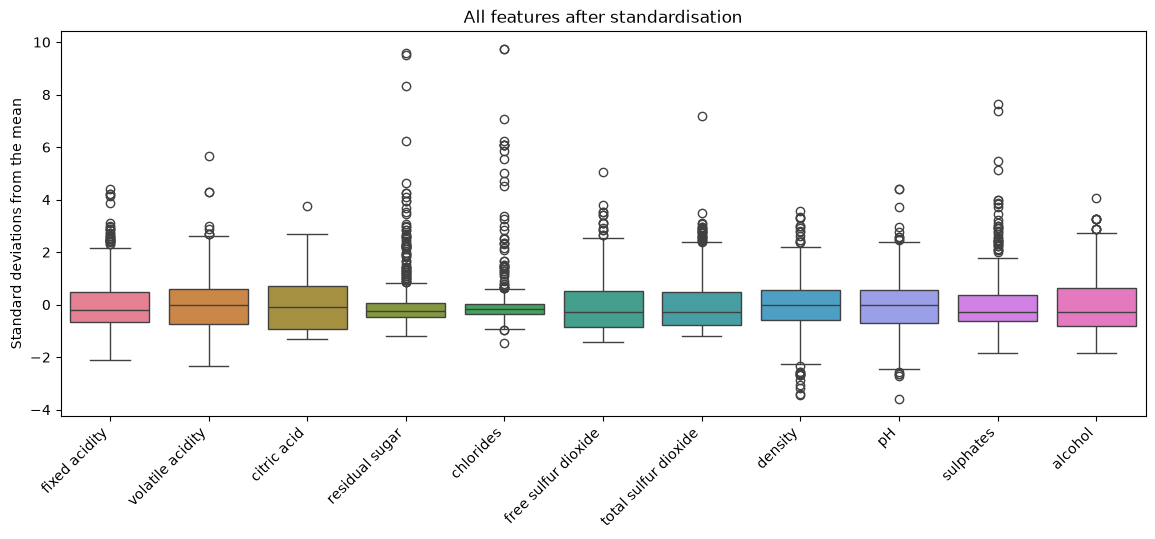

In [39]:
scaled = pd.DataFrame(StandardScaler().fit_transform(X), columns=features) # standardize the features
plt.figure(figsize=(14, 5))
sns.boxplot(data=scaled)
plt.xticks(rotation=45, ha="right")
plt.title("All features after standardisation")
plt.ylabel("Standard deviations from the mean")
plt.show()

In [40]:
def evaluate(make_model, X, y, n_splits=50, scale=True, drop_outliers=False):
    """Score a model by averaging over many random train/validation splits.

    The course rules forbid GridSearchCV and cross_val_score, so this is our own replacement. 
    We repeat the split n_splits times with a different random_state each pass and average the results. 
    Lecture 12 introduces this as the stand-in for k-fold cross-validation.

    Because random_state counts 0, 1, 2, ..., every model passed to this
    function sees the identical set of splits. That is what makes comparing
    different classifiers in section 7 a fair test.

    Parameters
    ----------
    make_model : callable
        A no-argument function that RETURNS a new, unfitted model, for example
        lambda: LogisticRegression(C=1, max_iter=1000). It has to be a function
        rather than a model object so that every split gets a fresh estimator
        with no weights left over from the previous pass.
    X : ndarray, shape (n_samples, n_features)
        The cleaned feature matrix.
    y : ndarray, shape (n_samples,)
        The 0/1 quality labels.
    n_splits : int, default 50
        How many random splits to average over. Drop to about 10 while
        exploring a large grid, then raise it back for the numbers reported here.
    scale : bool, default True
        Standardise the features. True for distance- and gradient-based models
        (KNN, SVC, logistic regression, perceptron). False for decision trees
        and random forests, which split one feature at a time on a threshold
        and are therefore unaffected by rescaling.
    drop_outliers : bool, default False
        Remove training rows where any feature lies more than 3 standard
        deviations from its mean. Whether this helps is an empirical question,
        so it is an option to measure rather than something applied by default.

    Returns
    -------
    (float, float, float)
        Mean training accuracy, mean validation accuracy, and the standard
        deviation of validation accuracy across the splits. The gap between the
        first two shows overfitting; the third shows how stable the model is.
    """
    train_scores, val_scores = [], []
    for randome_split in range(n_splits):
        # 1. A new random split, the same one for every model
        # A different split each pass, but a reproducible one, since randome_split is the seed. 
        # stratify=y keeps the 50/50 class balance in both halves
        X_tr, X_va, y_tr, y_va = train_test_split(
            X, y, test_size=0.3, random_state=randome_split, stratify=y)
    
        # 2. Remove outliers from the training part only makes the test easier and flattens the score.
        if drop_outliers:
            z_tr = (X_tr - X_tr.mean(axis=0)) / X_tr.std(axis=0)
            keep = (np.abs(z_tr) < 3).all(axis=1)
            X_tr, y_tr = X_tr[keep], y_tr[keep]

        # 3. Scale with a scaler fitted on the training part only
        # fit_transform learns the mean and standard deviation; transform only applies them. Fitting on
        # the full data instead would let validation rows influence the transformation used on training rows. 
        # That is data leakage: it runs without any error and quietly makes the validation score optimistic.
        if scale:
            sc = StandardScaler()
            X_tr = sc.fit_transform(X_tr)
            X_va = sc.transform(X_va)
        

        # 4. A fresh model, trained and scored
        # A brand new model every pass. make_model() builds it here
        # so no weights survive from the previous split.
        model = make_model()
        model.fit(X_tr, y_tr)
        train_scores.append(model.score(X_tr, y_tr))
        val_scores.append(model.score(X_va, y_va))

    # np.std measures spread across the splits: a large value means the model's
    # accuracy depends heavily on which rows it happened to train on.
    return np.mean(train_scores), np.mean(val_scores), np.std(val_scores)

tr, va, sd = evaluate(lambda: LogisticRegression(max_iter=1000), X, y)
print(f"train {tr:.3f}, validation {va:.3f} ± {sd:.3f}")

train 0.750, validation 0.743 ± 0.028


### 7. Evaluating different models and hyperparameters (using train/test splits)

In [41]:
results = []   # run ONCE; every tuning cell appends to this

In [42]:

# Tune the learning rate (eta0) for the Perceptron
for eta in [0.0001, 0.001, 0.01, 0.1, 1.0]:
    tr, va, sd = evaluate(lambda: Perceptron(eta0=eta, max_iter=100, random_state=1), X, y)
    results.append({"model": "Perceptron", "settings": f"eta0={eta}",
                    "train": tr, "val": va, "std": sd})

In [43]:
# Tune the regularization strength (C) for the Logistic Regression
for c in [0.001, 0.01, 0.1, 1, 10, 100, 1000]:
    tr, va, sd = evaluate(lambda: LogisticRegression(C=c, max_iter=1000), X, y)
    results.append({"model": "Logistic regression", "settings": f"C={c}",
                    "train": tr, "val": va, "std": sd})

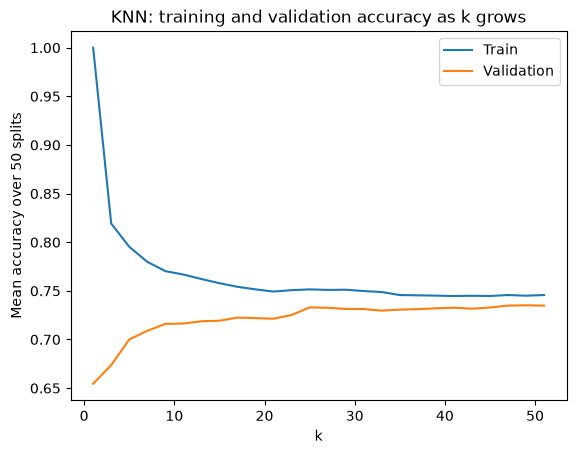

In [44]:
# Tune the number of neighbors (k) and distance metric (p) for the KNN
for k in range(1, 52, 2):          # odd k from 1 to 51
    for p in [1, 2]:               # 1 = Manhattan, 2 = Euclidean
        tr, va, sd = evaluate(lambda: KNeighborsClassifier(n_neighbors=k, p=p), X, y)
        results.append({"model": "KNN", "settings": f"k={k}, p={p}", "k": k, "p": p,
                        "train": tr, "val": va, "std": sd})

# Training vs validation accuracy as k grows (Euclidean distance)
res = pd.DataFrame(results)
knn_p2 = res[(res["model"] == "KNN") & (res["p"] == 2)]
plt.plot(knn_p2["k"], knn_p2["train"], label="Train")
plt.plot(knn_p2["k"], knn_p2["val"], label="Validation")
plt.xlabel("k")
plt.ylabel("Mean accuracy over 50 splits")
plt.title("KNN: training and validation accuracy as k grows")
plt.legend()
plt.show()

In [45]:
# DecisionTree
from sklearn.tree import DecisionTreeClassifier

# evaluating different maximum tree depths using the repeated train/validation splits  in evaluate()
for depth in [2, 3, 4, 5, 6, 8, 10, None]:

    tr, va, sd = evaluate(
        lambda: DecisionTreeClassifier(
            criterion='gini',
            max_depth=depth,
            random_state=1
        ),
        X, y,
        scale=False
    )
# saving the scores 
    results.append({
        "model": "Decision Tree",
        "settings": f"max_depth={depth}",
        "train": tr,
        "val": va,
        "std": sd
    })

In [46]:
# Random forest 

from sklearn.ensemble import RandomForestClassifier

# looping through combinations of n_estimators and max_depth and evaluating each Random Forest
for depth in [3, 5, 10, None]:
    for n in [50, 100, 200]:

        tr, va, sd = evaluate(
            lambda: RandomForestClassifier(
                n_estimators=n,
                criterion='gini',
                max_depth=depth,
                random_state=1,
                n_jobs=-1
            ),
            X, y,
            scale=False
        )
# saving the scores 
        results.append({
            "model": "Random Forest",
            "settings": f"n_estimators={n}, max_depth={depth}",
            "train": tr,
            "val": va,
            "std": sd
        })

In [47]:
# SVC
from sklearn.svm import SVC

# Test linear and rbf kernels, each with 5 different regularization (c) values
for kernel in ['linear', 'rbf']:
    for c in [0.01, 0.1, 1, 10, 100]:

        tr, va, sd = evaluate(
            lambda: SVC(
                kernel=kernel,
                C=c,
                gamma='scale',
                random_state=1
            ),
            X, y
        )
# saving the scores 
        results.append({
            "model": "SVM",
            "settings": f"kernel={kernel}, C={c}",
            "train": tr,
            "val": va,
            "std": sd
        })

In [48]:
# Comparing the 6 classifiers 

results_df = pd.DataFrame(results)

best_models = (
    results_df
    .sort_values("val", ascending=False)
    .drop_duplicates(subset="model")
    .sort_values("val", ascending=False)
)

print(best_models.to_string(index=False))

# Random forest is currently the best classifier with 0.755614 accurasy, but it also has a big gap between val and train (about 10%) which can suggest some overfitting. Still it can be a good candidate model. 
# Logistic regression has the least val and train gap (about 1%) which suggests if generalizes better although having a slightly lower accuracy of 0.743158. It can also be a potential candidate. 
# Perceptron has the lowest validation accuracy (0.663158) and the biggest standard deviasion (0.054060)

              model                      settings    train      val      std    k   p
      Random Forest n_estimators=200, max_depth=5 0.860677 0.755614 0.021807  NaN NaN
                SVM               kernel=rbf, C=1 0.802556 0.746579 0.022317  NaN NaN
Logistic regression                          C=10 0.750489 0.743158 0.028332  NaN NaN
                KNN                     k=43, p=1 0.752707 0.742719 0.026310 43.0 1.0
      Decision Tree                   max_depth=4 0.789211 0.723246 0.026392  NaN NaN
         Perceptron                      eta0=0.1 0.672481 0.663158 0.054060  NaN NaN


### 8. Final evaluation

The tuning in section 7 trained on 70% of the data in each split and held 30% back to measure with. That measuring is now finished, so the final model is trained on all 760 cleaned rows: more data gives a better model, and there is nothing left to hold out for.

The random forest needs no scaling. A tree splits one feature at a time on a threshold, so rescaling a feature cannot change which split is best. That removes the scaler from the final pipeline entirely, and with it the most common way of leaking information into a test set.

In [49]:
best_model = RandomForestClassifier(
    n_estimators=200, max_depth=5, random_state=1, n_jobs=-1
)

X_full = data[features].to_numpy()        # all 760 cleaned rows
X_test = test[features].to_numpy()        # same 11 columns, same order, untouched

best_model.fit(X_full, y)

print("trained on", X_full.shape[0], "rows x", X_full.shape[1], "features")
print("accuracy on the full training set:", round(best_model.score(X_full, y), 4))
print("test matrix ready:", X_test.shape)

importance = (pd.Series(best_model.feature_importances_, index=features)
                .sort_values(ascending=False).round(3))
print("\nwhich features the forest actually used:")
print(importance.to_string())

# Train our best classifier on the full cleaned training dataset
final_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=5,
    random_state=1
)

final_model.fit(X, y)

# Predict the Kaggle test data
X_test = test[features].to_numpy()
predictions = final_model.predict(X_test)

# Use Kaggle's sample submission to preserve the required format
submission = sample.copy()
submission.iloc[:, -1] = predictions

# Save the submission file
submission.to_csv("submission.csv", index=False)

print(submission.head())
print("Submission shape:", submission.shape)

trained on 760 rows x 11 features
accuracy on the full training set: 0.8355
test matrix ready: (209, 11)

which features the forest actually used:
alcohol                 0.261
sulphates               0.189
total sulfur dioxide    0.117
volatile acidity        0.106
density                 0.087
chlorides               0.064
pH                      0.044
fixed acidity           0.043
citric acid             0.033
free sulfur dioxide     0.030
residual sugar          0.026
   ID  quality
0   0        1
1   1        1
2   2        0
3   3        0
4   4        0
Submission shape: (209, 2)


### 9. Kaggle submission

The submission format is taken from the example code on the competition's Overview page: a column named `Quality`, with the DataFrame index named `ID`, written out so that the row numbers 0 to 208 become the ID column.

This is worth stating because two other sources in the folder point elsewhere. `sample_submission.csv` carries the right IDs but spells the target `quality` in lower case, and an upload in that form is rejected. The `Id` column in `test.csv`, which runs 1117, 1411 and so on, is not what the scorer keys on either.

No cleaning is applied to `test.csv`. Every row has to receive a prediction, so removing duplicates or outliers there would leave gaps the submission cannot have. Selecting `test[features]` preserves the original row order, so prediction *i* belongs to row *i*.

In [52]:
# Submission format copied from the example code on the competition's Overview page:
#     y_test = pd.DataFrame(y_test, columns=["Quality"])
#     y_test.index.name = "Id"
#     y_test[['Quality']].to_csv("submission.csv")
y_pred_kaggle = best_model.predict(X_test)

y_test = pd.DataFrame(y_pred_kaggle, columns=["quality"])
y_test.index.name = "Id"                     # row numbers 0..208 become the ID column
y_test[["quality"]].to_csv("submission.csv")

# checks before uploading
check = pd.read_csv("submission.csv")
sample = pd.read_csv("sample_submission.csv")
print("header:            ", ",".join(check.columns))
print("shape:             ", check.shape, "  (expected (209, 2))")
print("IDs match sample:  ", check["Id"].tolist() == sample["ID"].tolist())
print("missing values:    ", int(check.isna().sum().sum()))
print("predicted classes: ", check["quality"].value_counts().to_dict())
print()
print(check.head().to_string(index=False))

header:             Id,quality
shape:              (209, 2)   (expected (209, 2))
IDs match sample:   True
missing values:     0
predicted classes:  {1: 105, 0: 104}

 Id  quality
  0        1
  1        1
  2        0
  3        0
  4        0
